In [7]:
import pandas as pd

# load the csv
clean_teleco_df = pd.read_csv("../data/clean_teleco_df.csv")

In [8]:
# identify churn
clean_teleco_df["Churn"].value_counts(normalize=True)

Churn
0    0.734215
1    0.265785
Name: proportion, dtype: float64

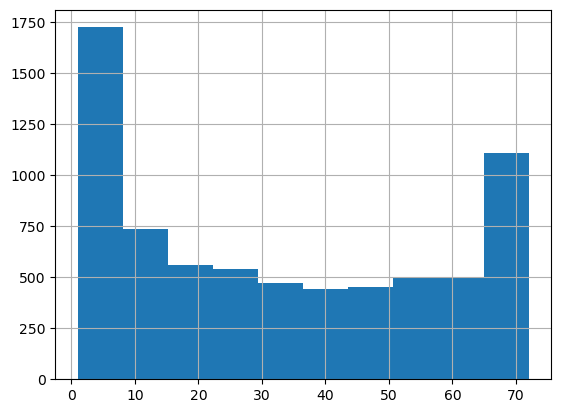

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# visualize tenure distribution
clean_teleco_df["tenure"].hist()
plt.show()

<Axes: xlabel='Churn', ylabel='tenure'>

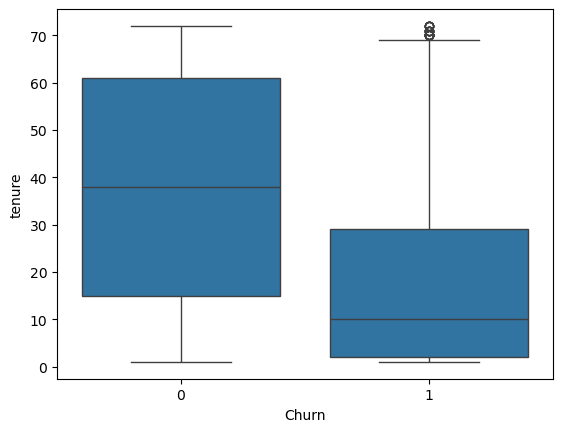

In [10]:
import seaborn as sns

# tenure box plot
sns.boxplot(x="Churn", y="tenure", data=clean_teleco_df)

Contract_One year
0    0.306295
1    0.112772
Name: Churn, dtype: float64
Contract_Two year
0    0.340565
1    0.028487
Name: Churn, dtype: float64


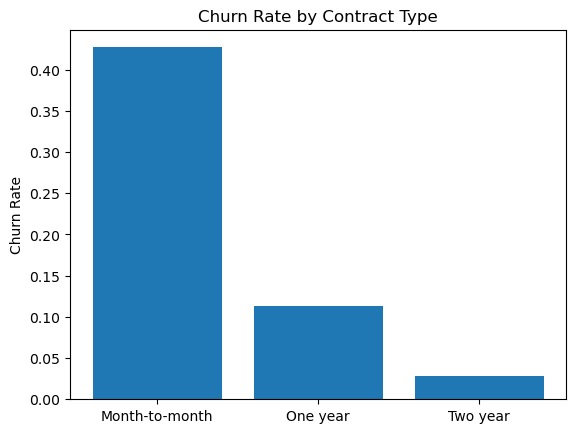

In [ ]:
# contract churn rate

print(clean_teleco_df.groupby("Contract_One year")["Churn"].mean())

# one year has ~11% churn
print(clean_teleco_df.groupby("Contract_Two year")["Churn"].mean())

contract_churn = {
    "Month-to-month": clean_teleco_df[(clean_teleco_df["Contract_One year"]==0) & (clean_teleco_df["Contract_Two year"]==0)]["Churn"].mean(),
    "One year": clean_teleco_df[clean_teleco_df["Contract_One year"]==1]["Churn"].mean(),
    "Two year": clean_teleco_df[clean_teleco_df["Contract_Two year"]==1]["Churn"].mean()
}

plt.bar(contract_churn.keys(), contract_churn.values())
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn Rate")
plt.show()

In [14]:
# internet churn rate

clean_teleco_df.groupby("InternetService_Fiber optic")["Churn"].mean()

# fiber users have ~41.9% churn
# non-fiber users have ~14.5% churn

InternetService_Fiber optic
0    0.145325
1    0.418928
Name: Churn, dtype: float64

In [ ]:
# payment method churn rate

clean_teleco_df.groupby("PaymentMethod_Electronic check")["Churn"].mean()

PaymentMethod_Electronic check
0    0.170988
1    0.452854
Name: Churn, dtype: float64

In [16]:
# senior citizen churn rate

clean_teleco_df.groupby("SeniorCitizen")["Churn"].mean()

SeniorCitizen
0    0.236503
1    0.416813
Name: Churn, dtype: float64

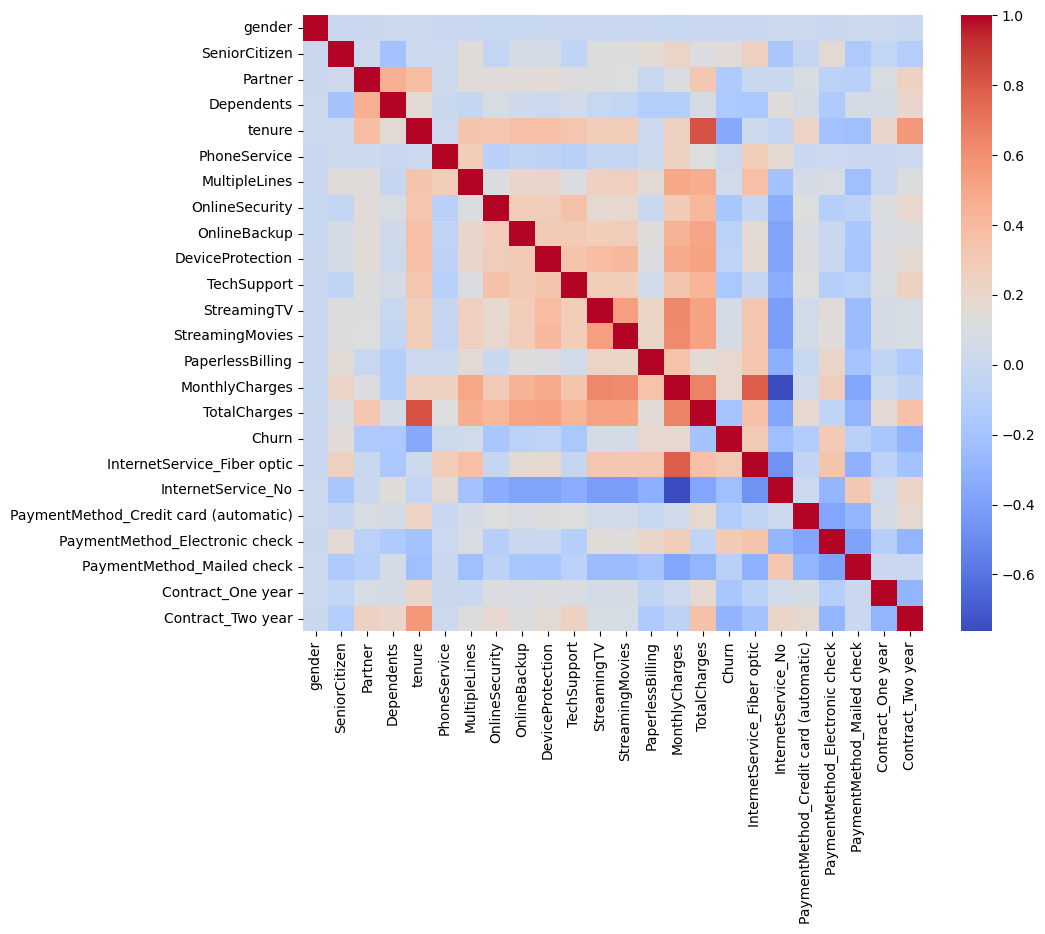

tenure                                  -0.354049
Contract_Two year                       -0.301552
InternetService_No                      -0.227578
TotalCharges                            -0.199484
Contract_One year                       -0.178225
OnlineSecurity                          -0.171270
TechSupport                             -0.164716
Dependents                              -0.163128
Partner                                 -0.149982
PaymentMethod_Credit card (automatic)   -0.134687
PaymentMethod_Mailed check              -0.090773
OnlineBackup                            -0.082307
DeviceProtection                        -0.066193
gender                                  -0.008545
PhoneService                             0.011691
MultipleLines                            0.040033
StreamingMovies                          0.060860
StreamingTV                              0.063254
SeniorCitizen                            0.150541
PaperlessBilling                         0.191454


In [20]:
# dataset correlation heatmap

numeric_df = clean_teleco_df.select_dtypes(include=["number"])

plt.figure(figsize=(10,8))
sns.heatmap(numeric_df.corr(), cmap="coolwarm")

plt.show()
print(clean_teleco_df.corr()["Churn"].sort_values())

In [21]:
print(clean_teleco_df.groupby(["Contract_One year", "Churn"])["tenure"].mean())
print(clean_teleco_df.groupby(["InternetService_Fiber optic", "PaymentMethod_Electronic check"])["Churn"].mean())

Contract_One year  Churn
0                  0        36.276640
                   1        15.348796
1                  0        41.705972
                   1        44.963855
Name: tenure, dtype: float64
InternetService_Fiber optic  PaymentMethod_Electronic check
0                            0                                 0.110550
                             1                                 0.288312
1                            0                                 0.298468
                             1                                 0.532288
Name: Churn, dtype: float64


In [22]:
# feature engineering

clean_teleco_df["HighRisk"] = (
    (clean_teleco_df["tenure"] < 12) &
    (clean_teleco_df["Contract_One year"] == 0) &
    (clean_teleco_df["Contract_Two year"] == 0)
)
clean_teleco_df.groupby("HighRisk")["Churn"].mean()

HighRisk
False    0.171351
True     0.519392
Name: Churn, dtype: float64

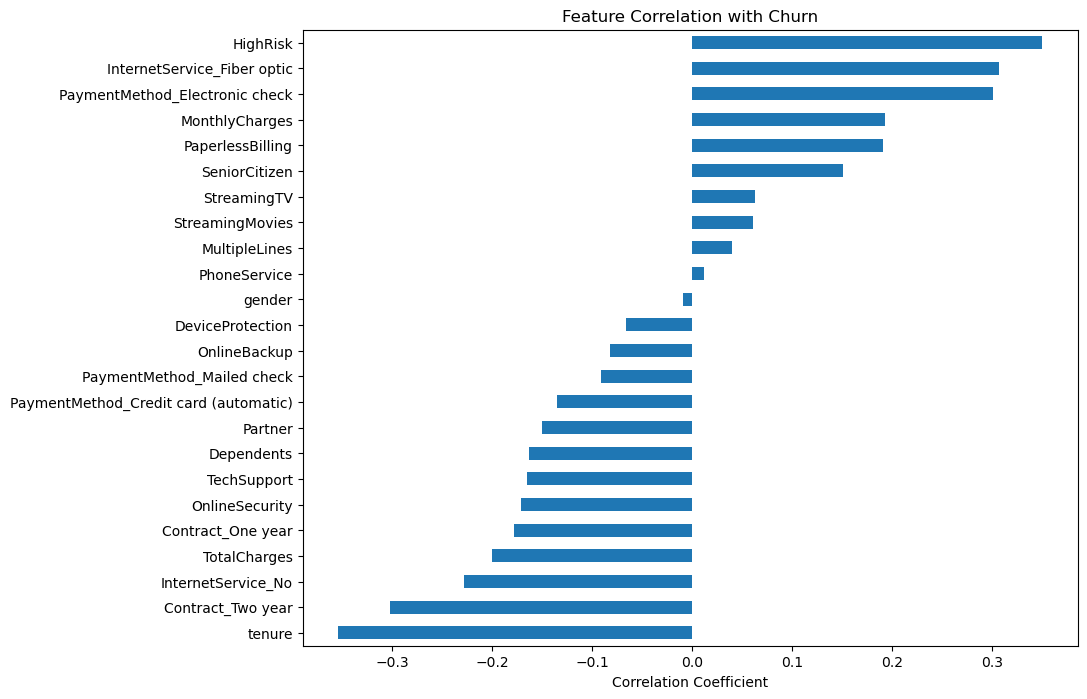

In [ ]:
# feature correlation with churn

corr = clean_teleco_df.corr()["Churn"].drop("Churn").sort_values()

plt.figure(figsize=(10,8))
corr.plot(kind="barh")
plt.title("Feature Correlation with Churn")
plt.xlabel("Correlation Coefficient")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# train/test split
X = clean_teleco_df.drop("Churn", axis=1)
y = clean_teleco_df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# scale features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# training baseline logistic regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

# making predictions
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [28]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# accuracy
print(accuracy_score(y_test, y_pred))

# confusion matrix
print(confusion_matrix(y_test, y_pred))

# classification report
print(classification_report(y_test, y_pred))

# ROC AUC
print(roc_auc_score(y_test, y_prob))

0.7882018479033405
[[912 121]
 [177 197]]
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1033
           1       0.62      0.53      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

0.8332966646132184


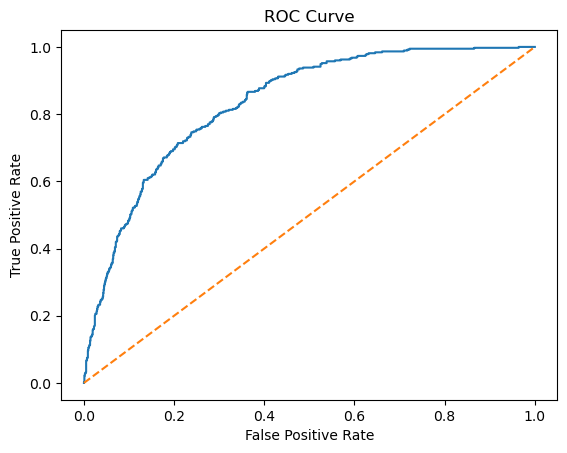

,Feature,Coefficient
16,InternetService_Fiber optic,0.696920
23,HighRisk,0.305992
15,TotalCharges,0.302061
11,StreamingTV,0.245496
12,StreamingMovies,0.233883
6,MultipleLines,0.232402
19,PaymentMethod_Electronic check,0.177338
13,PaperlessBilling,0.143670
1,SeniorCitizen,0.074872
9,DeviceProtection,0.073672


In [30]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr)
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

# interpreting

import pandas as pd

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
}).sort_values(by="Coefficient", ascending=False)

coefficients


In [31]:
from sklearn.metrics import classification_report, confusion_matrix

# optimized threshold
y_pred_03 = (y_prob > 0.3).astype(int)
print(confusion_matrix(y_test, y_pred_03))
print(classification_report(y_test, y_pred_03))

[[761 272]
 [ 89 285]]
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1033
           1       0.51      0.76      0.61       374

    accuracy                           0.74      1407
   macro avg       0.70      0.75      0.71      1407
weighted avg       0.79      0.74      0.76      1407



In [33]:
from sklearn.ensemble import RandomForestClassifier
# random forest classifier
rf = RandomForestClassifier()
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

In [ ]:
from sklearn.metrics import roc_auc_score, classification_report

print(classification_report(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

ROC-AUC: 0.8158794539553039


In [35]:
import pandas as pd

rf_importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

rf_importance.head(10)

TotalCharges                      0.181084
MonthlyCharges                    0.169187
tenure                            0.151291
HighRisk                          0.047402
InternetService_Fiber optic       0.043736
PaymentMethod_Electronic check    0.040937
Contract_Two year                 0.030567
gender                            0.028876
PaperlessBilling                  0.026371
Partner                           0.022405
dtype: float64

In [36]:
# tuning

rf_tuned = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

rf_tuned.fit(X_train, y_train)

rf_tuned_pred = rf_tuned.predict(X_test)
rf_tuned_prob = rf_tuned.predict_proba(X_test)[:,1]

print(classification_report(y_test, rf_tuned_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_tuned_prob))

              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1033
           1       0.65      0.49      0.56       374

    accuracy                           0.79      1407
   macro avg       0.74      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

ROC-AUC: 0.8380799913030423


In [39]:
import sys
!{sys.executable} -m pip install xgboost

import xgboost

In [41]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    random_state=42,
    use_label_encoder=False,
    eval_metric="logloss"
)

xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)
xgb_prob = xgb.predict_proba(X_test)[:, 1]

c:\Users\dillo\anaconda3\envs\ChurnDsProj\Lib\site-packages\xgboost\training.py:200: UserWarning: [12:22:27] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [44]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, xgb_pred))
print("ROC-AUC:", roc_auc_score(y_test, xgb_prob))

              precision    recall  f1-score   support

           0       0.82      0.86      0.84      1033
           1       0.56      0.49      0.53       374

    accuracy                           0.76      1407
   macro avg       0.69      0.68      0.68      1407
weighted avg       0.76      0.76      0.76      1407

ROC-AUC: 0.8156594416346138


In [47]:
import numpy as np

# threshold tuning
xgb_tuned = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb_tuned.fit(X_train, y_train)
xgb_tuned_pred = xgb_tuned.predict(X_test)
xgb_tuned_prob = xgb_tuned.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.1, 0.9, 0.1)

for t in thresholds:
    y_pred_t_tuned = (xgb_tuned_prob > t).astype(int)
    print(f"\nThreshold: {t}")
    print(classification_report(y_test, y_pred_t_tuned))


Threshold: 0.1
              precision    recall  f1-score   support

           0       0.96      0.50      0.65      1033
           1       0.40      0.94      0.56       374

    accuracy                           0.61      1407
   macro avg       0.68      0.72      0.61      1407
weighted avg       0.81      0.61      0.63      1407


Threshold: 0.2
              precision    recall  f1-score   support

           0       0.92      0.65      0.76      1033
           1       0.46      0.84      0.60       374

    accuracy                           0.70      1407
   macro avg       0.69      0.74      0.68      1407
weighted avg       0.80      0.70      0.72      1407


Threshold: 0.30000000000000004
              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1033
           1       0.51      0.77      0.61       374

    accuracy                           0.74      1407
   macro avg       0.70      0.75      0.71      1407
weighted a

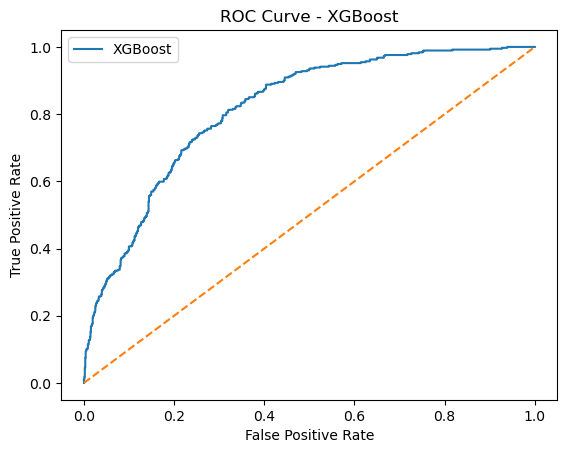

In [ ]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# ROC curve for XGBoost
fpr_xgb, tpr_xgb, thresholds_xgb = roc_curve(y_test, xgb_prob)

plt.figure()
plt.plot(fpr_xgb, tpr_xgb, label="XGBoost")
plt.plot([0,1], [0,1], linestyle="--")  # random model baseline
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.legend()
plt.show()

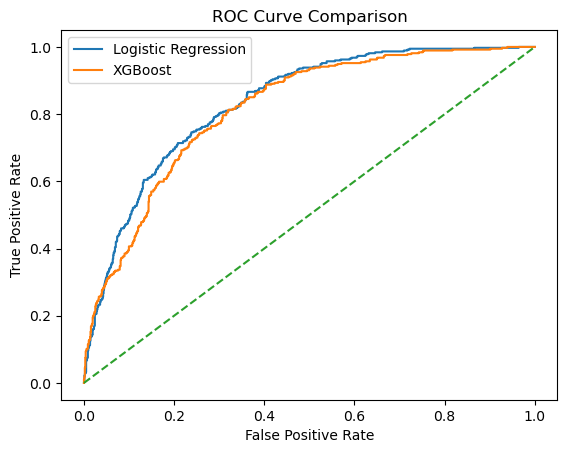

In [49]:
from sklearn.metrics import roc_curve

# Logistic
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob)

# XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_prob)

plt.figure()
plt.plot(fpr_log, tpr_log, label="Logistic Regression")
plt.plot(fpr_xgb, tpr_xgb, label="XGBoost")
plt.plot([0,1], [0,1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

HighRisk                       0.575838
InternetService_Fiber optic    0.199604
Contract_Two year              0.053245
Contract_One year              0.032832
InternetService_No             0.029850
StreamingMovies                0.008880
StreamingTV                    0.007629
tenure                         0.007536
MultipleLines                  0.007372
OnlineSecurity                 0.006316
dtype: float32


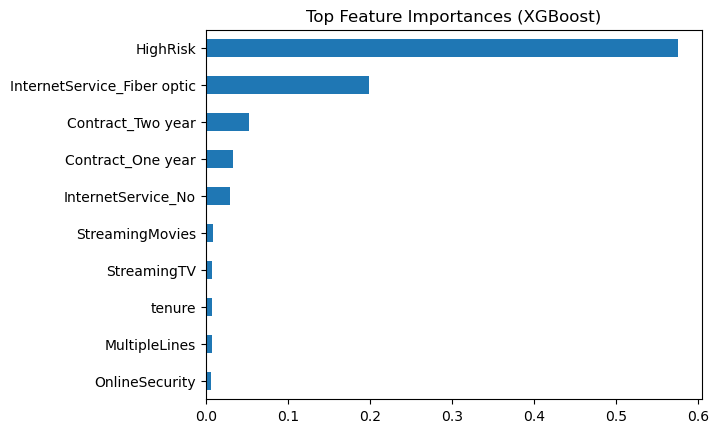

In [52]:
import pandas as pd
import matplotlib.pyplot as plt

xgb_importance = pd.Series(
    xgb.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(xgb_importance.head(10))

xgb_importance.head(10).plot(kind="barh")
plt.title("Top Feature Importances (XGBoost)")
plt.gca().invert_yaxis()
plt.show()

In [54]:
import sys
!{sys.executable} -m pip install shap

import shap

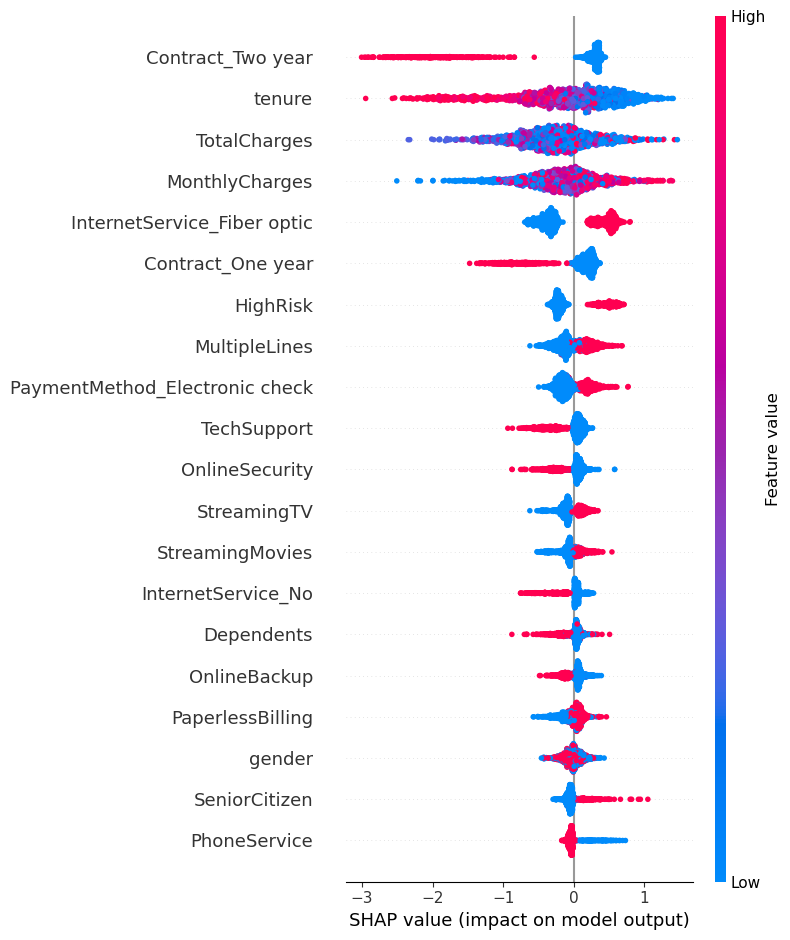

In [55]:
import shap

# shap analysis
explainer = shap.Explainer(xgb)
shap_values = explainer(X_test)

shap.summary_plot(shap_values, X_test)

In [57]:
# export dashboard csv

df_raw = pd.read_csv("../data/Teleco Customer Churn.csv")
df_raw = df_raw[pd.to_numeric(df_raw["TotalCharges"], errors="coerce").notna()].reset_index(drop=True)

clean_teleco_df["Contract"] = df_raw["Contract"].values
clean_teleco_df["InternetService"] = df_raw["InternetService"].values
clean_teleco_df["PaymentMethod"] = df_raw["PaymentMethod"].values

clean_teleco_df["churn_probability"] = model.predict_proba(X)[:, 1]
clean_teleco_df.to_csv("../data/churn_dashboard_data.csv", index=False)

clean_teleco_df

c:\Users\dillo\anaconda3\envs\ChurnDsProj\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Contract_One year,Contract_Two year,HighRisk,Contract,InternetService,PaymentMethod,churn_probability
0,0,0,1,0,1,0,0,0,1,0,...,0,1,0,0,0,True,Month-to-month,DSL,Electronic check,0.000002
1,1,0,0,0,34,1,0,1,0,1,...,0,0,1,1,0,False,One year,DSL,Mailed check,1.000000
2,1,0,0,0,2,1,0,1,1,0,...,0,0,1,0,0,True,Month-to-month,DSL,Mailed check,0.000835
3,1,0,0,0,45,0,0,1,0,1,...,0,0,0,1,0,False,One year,DSL,Bank transfer (automatic),1.000000
4,0,0,0,0,2,1,0,0,0,0,...,0,1,0,0,0,True,Month-to-month,Fiber optic,Electronic check,0.011864
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7027,1,0,1,1,24,1,1,1,0,1,...,0,0,1,1,0,False,One year,DSL,Mailed check,1.000000
7028,0,0,1,1,72,1,1,0,1,1,...,1,0,0,1,0,False,One year,Fiber optic,Credit card (automatic),1.000000
7029,0,0,1,1,11,0,0,1,0,0,...,0,1,0,0,0,True,Month-to-month,DSL,Electronic check,1.000000
7030,1,1,1,0,4,1,1,0,0,0,...,0,0,1,0,0,True,Month-to-month,Fiber optic,Mailed check,1.000000
